# Exploratory Data Analysis — House Sale Price Regression

**Dataset:** `synthetic_data_208.csv` (1,000 rows × 9 columns)
**Target:** `house_sale_price` (continuous → regression)

**Goal of this notebook:** understand the data, find quality issues, and identify the patterns that should drive
preprocessing and feature engineering. No final model is trained here; a few quick cross-validated linear fits are used
only as *diagnostics* to test hypotheses about functional form.

> Note: the project brief refers to "the None problem". That is an unfilled template placeholder. This notebook treats the
> problem as **predicting `house_sale_price` from property and neighbourhood attributes**.

## Contents
1. Setup & loading
2. Structure and schema
3. Data quality audit
4. Target variable analysis
5. Univariate analysis — numeric features
6. Categorical feature — `location_type`
7. Bivariate analysis vs. target
8. Correlation & multicollinearity
9. Interactions with location
10. Outliers & influential points
11. Functional-form diagnostics (raw vs. log vs. log-log)
12. Feature relevance (mutual information & partial effects)
13. Summary of findings & recommendations

## 1. Setup & loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
RNG = 42

DATA_PATH = Path("synthetic_data_208.csv")
df = pd.read_csv(DATA_PATH)
TARGET = "house_sale_price"
NUM = [c for c in df.select_dtypes("number").columns if c != TARGET]
CAT = ["location_type"]
print(df.shape)
df.head()

(1000, 9)


,property_size,number_of_bedrooms,number_of_bathrooms,location_type,age_of_property,proximity_to_public_transport,crime_rate_in_area,school_quality_score,house_sale_price
0,"3,208.370",2.580,2.640,Suburban,1.160,3.400,2.390,9.580,"588,356.350"
1,"3,470.770",3.930,3.970,Rural,8.430,0.098,8.020,7.730,"329,647.430"
2,"2,010.050",3.350,3.210,Suburban,7.170,0.596,6.460,6.890,"286,583.940"
3,"5,371.610",5.510,4.340,Urban,12.300,0.080,6.270,8.470,"539,618.710"
4,"3,395.100",4.440,4.580,Suburban,20.170,0.969,3.140,6.600,"369,688.590"


## 2. Structure and schema

In [2]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
    "example": df.iloc[0],
})
schema

,dtype,non_null,n_unique,example
property_size,float64,1000,996,"3,208.370"
number_of_bedrooms,float64,1000,435,2.580
number_of_bathrooms,float64,1000,453,2.640
location_type,str,1000,3,Suburban
age_of_property,float64,1000,889,1.160
proximity_to_public_transport,float64,1000,661,3.400
crime_rate_in_area,float64,1000,644,2.390
school_quality_score,float64,1000,499,9.580
house_sale_price,float64,1000,1000,"588,356.350"


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
property_size,"1,000.000","2,847.639","1,294.746",979.700,"1,954.308","2,617.490","3,334.802","11,545.780"
number_of_bedrooms,"1,000.000",3.547,1.444,1.020,2.290,3.585,4.780,6.000
number_of_bathrooms,"1,000.000",3.507,1.545,1.160,2.388,3.200,4.330,10.820
age_of_property,"1,000.000",20.119,14.179,0.536,9.645,16.545,26.485,85.510
proximity_to_public_transport,"1,000.000",1.984,1.895,0.006,0.584,1.435,2.833,11.450
crime_rate_in_area,"1,000.000",5.512,4.217,0.611,2.720,4.270,7.053,40.670
school_quality_score,"1,000.000",6.993,1.642,1.630,5.887,7.130,8.260,9.910
house_sale_price,"1,000.000","344,997.089","124,449.672","102,048.820","256,868.842","329,963.265","408,214.555","1,381,318.560"


**Observations**
- 8 numeric columns (all `float64`) and 1 categorical (`location_type`, 3 levels).
- `number_of_bedrooms` and `number_of_bathrooms` are stored as floats — checked in the next section.
- The target has 1,000 unique values (no repeated prices), and every numeric feature is strictly positive.

## 3. Data quality audit

### 3.1 Missing values and duplicates

In [4]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
    "negatives": (df.select_dtypes("number") < 0).sum().reindex(df.columns),
    "zeros": (df.select_dtypes("number") == 0).sum().reindex(df.columns),
})
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate rows ignoring target:", df.drop(columns=TARGET).duplicated().sum())
quality

Exact duplicate rows: 0
Duplicate rows ignoring target: 0


,missing,missing_%,negatives,zeros
property_size,0,0.000,0.000,0.000
number_of_bedrooms,0,0.000,0.000,0.000
number_of_bathrooms,0,0.000,0.000,0.000
location_type,0,0.000,NaN,NaN
age_of_property,0,0.000,0.000,0.000
proximity_to_public_transport,0,0.000,0.000,0.000
crime_rate_in_area,0,0.000,0.000,0.000
school_quality_score,0,0.000,0.000,0.000
house_sale_price,0,0.000,0.000,0.000


### 3.2 Count variables stored as continuous values

number_of_bedrooms: 99.0% non-integer | min=1.02 max=6.0
number_of_bathrooms: 99.5% non-integer | min=1.16 max=10.82


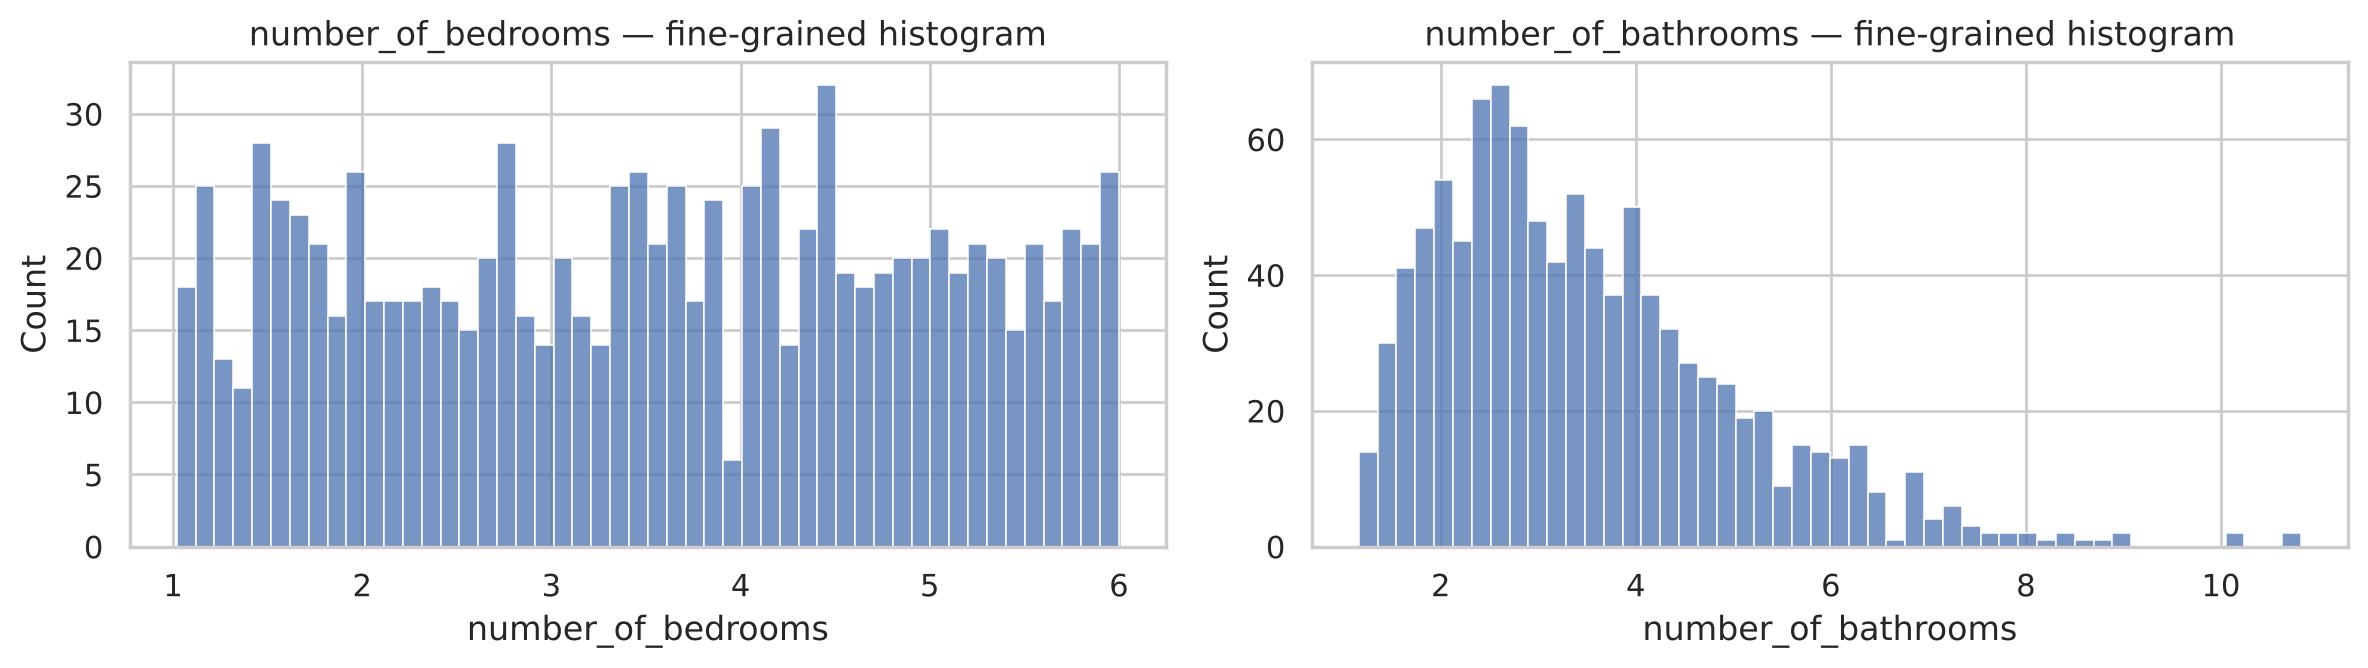

In [5]:
for c in ["number_of_bedrooms", "number_of_bathrooms"]:
    frac = (df[c] % 1 != 0).mean()
    print(f"{c}: {frac:.1%} non-integer | min={df[c].min()} max={df[c].max()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, c in zip(axes, ["number_of_bedrooms", "number_of_bathrooms"]):
    sns.histplot(df[c], bins=50, ax=ax)
    ax.set_title(f"{c} — fine-grained histogram")
plt.tight_layout(); plt.show()

Almost every bedroom/bathroom value is fractional (e.g. 2.58 bedrooms). Real listing data does not look like this; these
columns were generated as continuous noise around an integer-ish mean. **Decision for preprocessing:** keep them as
continuous features (rounding destroys information the generator encoded), but flag that a model trained on this data will not
transfer cleanly to real listings with integer counts.

### 3.3 Boundary clipping and pile-ups

In [6]:
edge = pd.DataFrame({
    "min": df[NUM + [TARGET]].min(),
    "n_at_min": [(df[c] == df[c].min()).sum() for c in NUM + [TARGET]],
    "max": df[NUM + [TARGET]].max(),
    "n_at_max": [(df[c] == df[c].max()).sum() for c in NUM + [TARGET]],
})
edge

,min,n_at_min,max,n_at_max
property_size,979.700,1,"11,545.780",1
number_of_bedrooms,1.020,2,6.000,4
number_of_bathrooms,1.160,1,10.820,1
age_of_property,0.536,1,85.510,1
proximity_to_public_transport,0.006,1,11.450,1
crime_rate_in_area,0.611,1,40.670,1
school_quality_score,1.630,1,9.910,1
house_sale_price,"102,048.820",1,"1,381,318.560",1


`number_of_bedrooms` has **4 rows at exactly 6.0** — a pile-up at the maximum that no other column shows. This indicates the
generator clipped bedrooms at 6. These rows are censored (the "true" value may be higher) — a small effect on 1,000 rows,
but tree models will treat 6.0 as a natural ceiling.

### 3.4 Logical consistency checks

In [7]:
checks = {
    "bathrooms > bedrooms": (df.number_of_bathrooms > df.number_of_bedrooms).sum(),
    "bathrooms > bedrooms + 2": (df.number_of_bathrooms > df.number_of_bedrooms + 2).sum(),
    "sqft per bedroom < 300": ((df.property_size / df.number_of_bedrooms) < 300).sum(),
    "school score outside 0-10": (~df.school_quality_score.between(0, 10)).sum(),
    "age > 80 years": (df.age_of_property > 80).sum(),
}
pd.Series(checks, name="rows_flagged").to_frame()

,rows_flagged
bathrooms > bedrooms,499
bathrooms > bedrooms + 2,41
sqft per bedroom < 300,1
school score outside 0-10,0
age > 80 years,1


In [8]:
df.loc[df.number_of_bathrooms > df.number_of_bedrooms + 2,
       ["property_size", "number_of_bedrooms", "number_of_bathrooms", "location_type", TARGET]] \
  .sort_values("number_of_bathrooms", ascending=False).head(10)

,property_size,number_of_bedrooms,number_of_bathrooms,location_type,house_sale_price
385,"11,545.780",6.000,10.820,Suburban,"1,381,318.560"
75,"10,199.120",5.890,10.670,Urban,"851,880.580"
486,"3,435.360",5.960,10.180,Urban,"462,599.510"
977,"8,536.720",5.960,10.090,Suburban,"848,881.390"
91,"8,184.750",6.000,8.930,Suburban,"975,398.160"
835,"6,747.520",5.950,8.910,Suburban,"817,183.030"
14,"5,565.400",5.640,8.790,Suburban,"543,806.720"
28,"4,541.920",5.590,8.660,Suburban,"558,694.210"
31,"5,787.130",5.860,8.500,Suburban,"724,047.780"
105,"4,826.480",4.720,8.360,Urban,"345,860.880"


A few dozen homes have far more bathrooms than bedrooms (up to 10.8 baths on a 6-bed house). These are concentrated in very
large properties, so they are plausible for the generator rather than data-entry errors. **Keep them**, but a ratio feature
(`bath_per_bed`) captures this better than raw counts.

## 4. Target variable analysis

count        1,000
mean       344,997
std        124,450
min        102,049
25%        256,869
50%        329,963
75%        408,215
max      1,381,319
Name: house_sale_price, dtype: str

Skewness: 1.633 | Excess kurtosis: 6.774
Skewness of log(price): 0.108


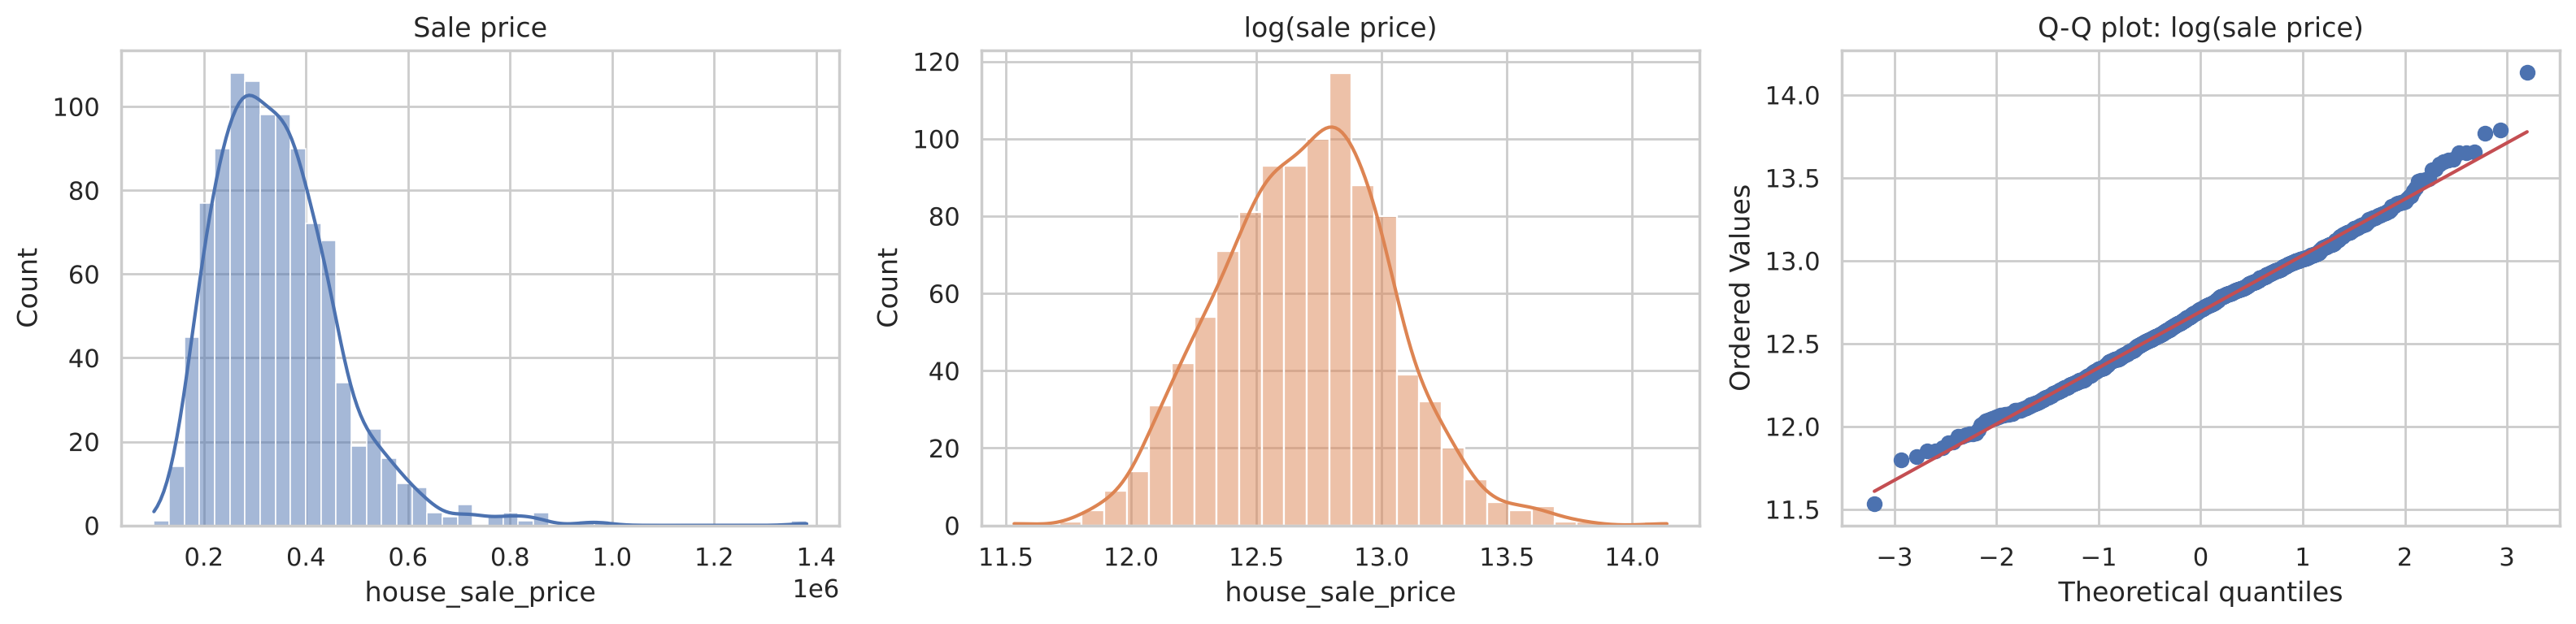

In [9]:
y = df[TARGET]
print(y.describe().apply(lambda v: f"{v:,.0f}"))
print(f"\nSkewness: {y.skew():.3f} | Excess kurtosis: {y.kurt():.3f}")
print(f"Skewness of log(price): {np.log(y).skew():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y, kde=True, ax=axes[0]); axes[0].set_title("Sale price")
sns.histplot(np.log(y), kde=True, ax=axes[1], color="C1"); axes[1].set_title("log(sale price)")
stats.probplot(np.log(y), dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot: log(sale price)")
plt.tight_layout(); plt.show()

In [10]:
for name, s in [("raw", y), ("log", np.log(y))]:
    stat, p = stats.normaltest(s)
    print(f"D'Agostino normality test ({name}): stat={stat:.1f}, p={p:.3g}")

D'Agostino normality test (raw): stat=382.2, p=9.95e-84
D'Agostino normality test (log): stat=4.1, p=0.127


**Finding:** price is strongly right-skewed (skew ≈ 1.6) with a long tail up to ~$1.38M. The log transform brings skew close
to zero and the Q-Q plot near-linear. **Model `log(price)`** and back-transform predictions (with a smearing correction if
reporting mean prices).

## 5. Univariate analysis — numeric features

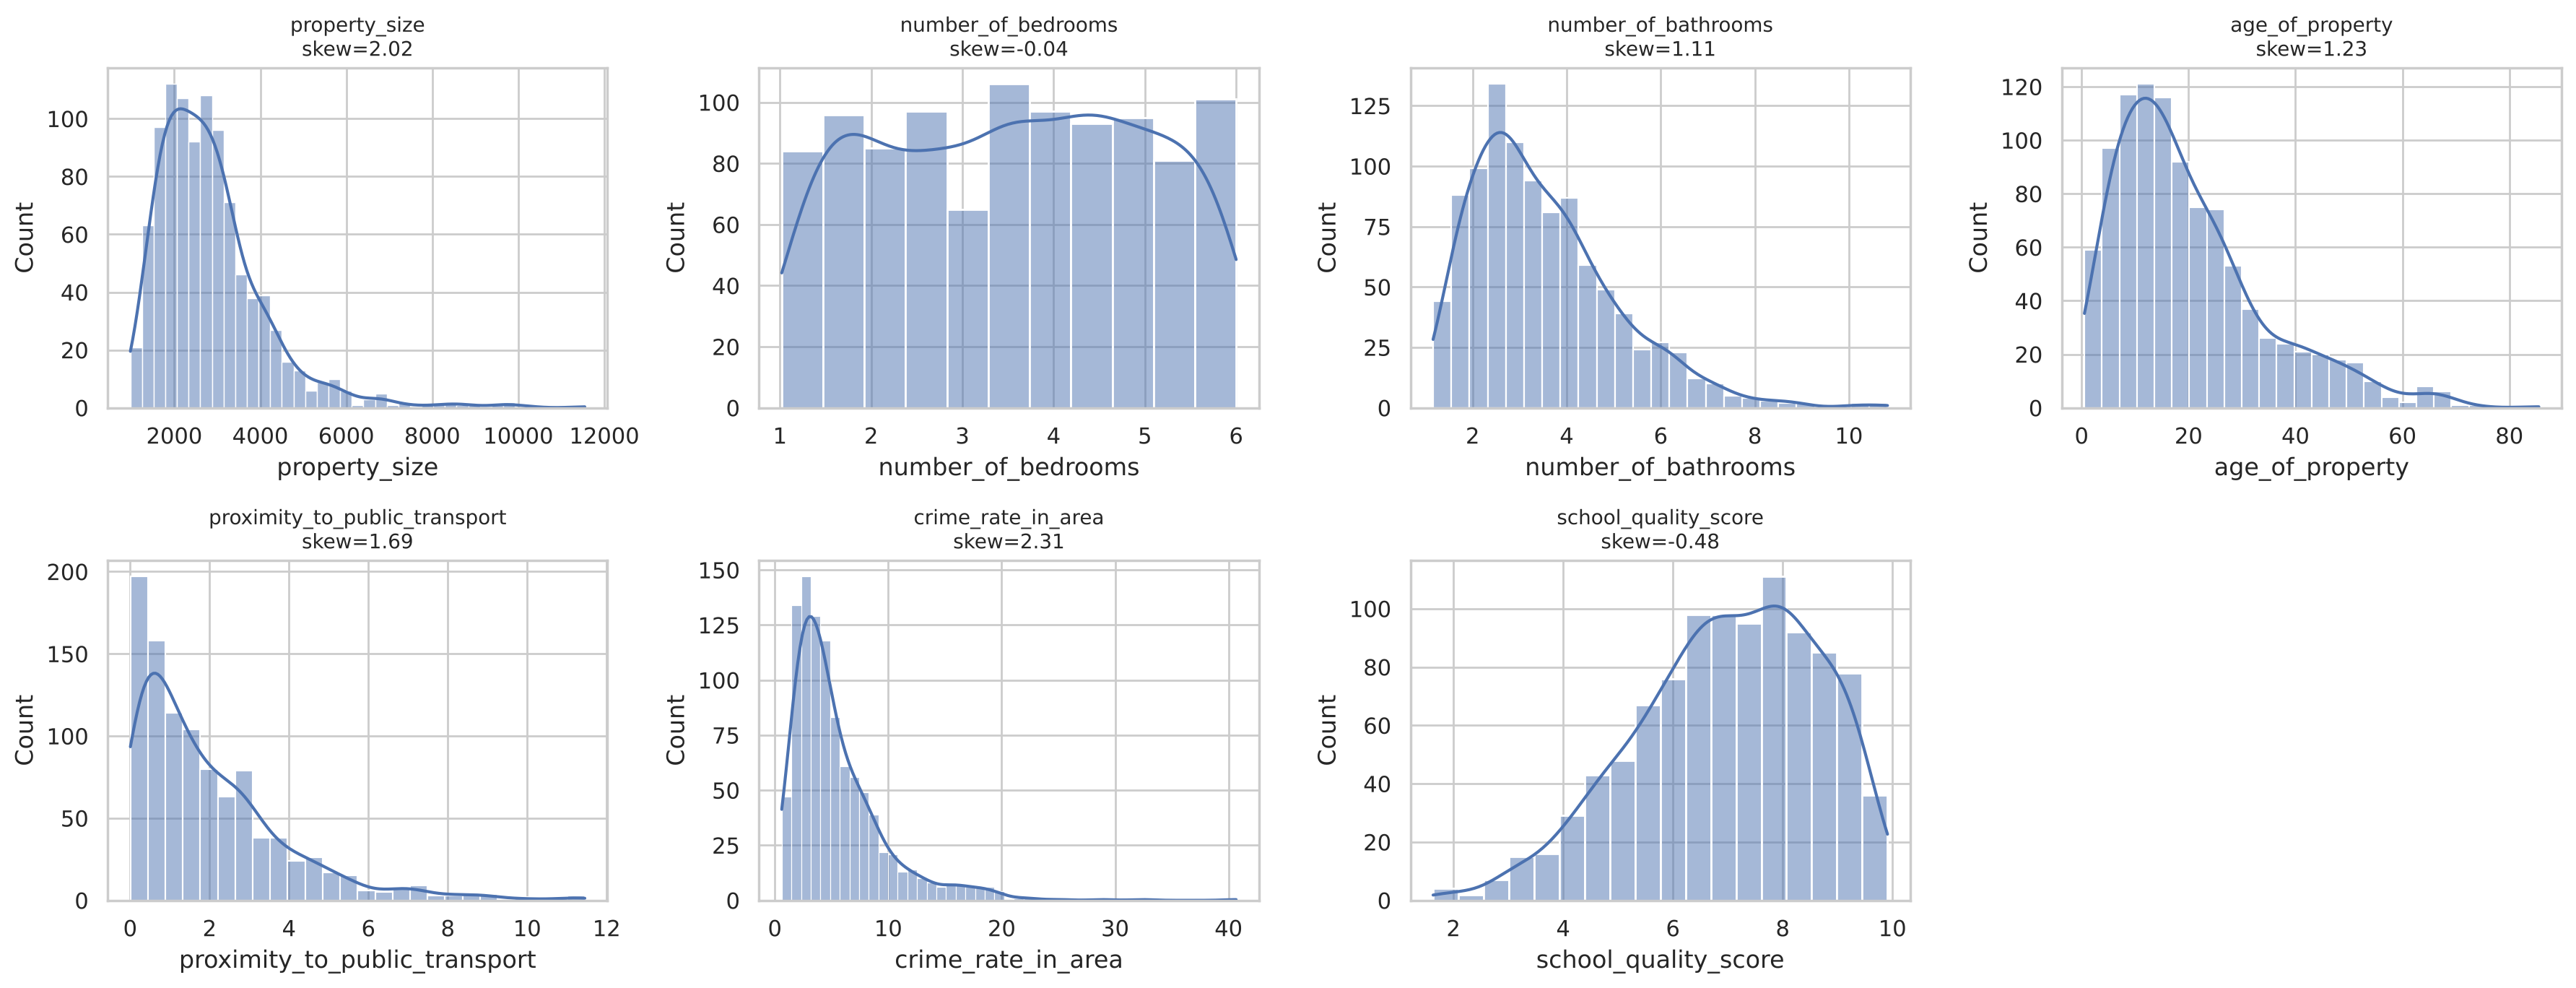

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), NUM):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(f"{c}\nskew={df[c].skew():.2f}", fontsize=10)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [12]:
skew_tbl = pd.DataFrame({
    "skew_raw": df[NUM].skew(),
    "skew_log": np.log(df[NUM]).skew(),
    "skew_sqrt": np.sqrt(df[NUM]).skew(),
}).sort_values("skew_raw", ascending=False)
skew_tbl

,skew_raw,skew_log,skew_sqrt
crime_rate_in_area,2.313,0.068,1.046
property_size,2.020,0.361,1.078
proximity_to_public_transport,1.692,-0.913,0.497
age_of_property,1.227,-0.743,0.386
number_of_bathrooms,1.114,0.045,0.548
number_of_bedrooms,-0.036,-0.639,-0.322
school_quality_score,-0.480,-1.316,-0.834


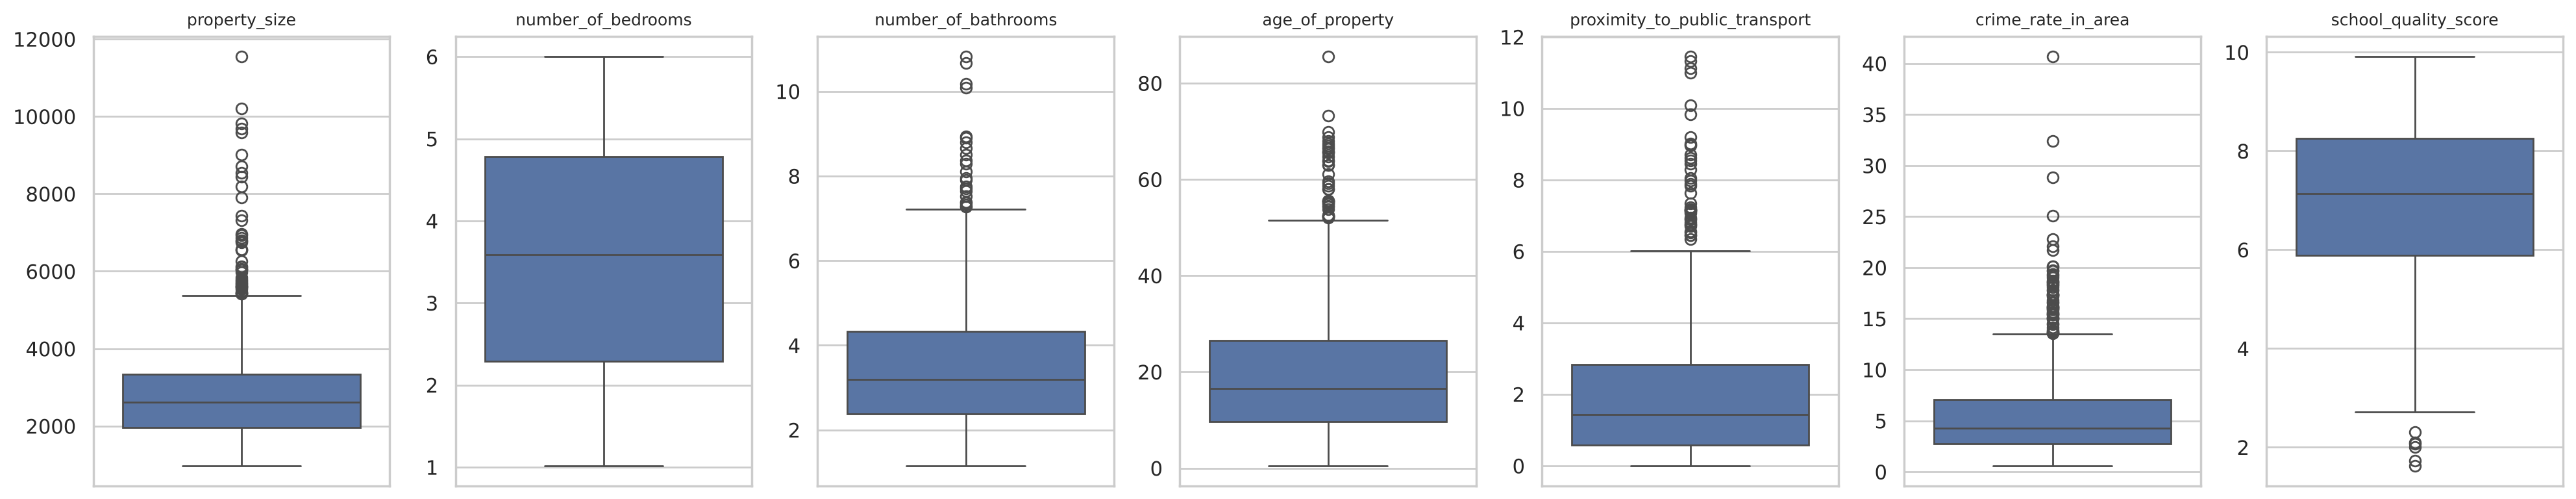

In [13]:
fig, axes = plt.subplots(1, len(NUM), figsize=(20, 4))
for ax, c in zip(axes, NUM):
    sns.boxplot(y=df[c], ax=ax); ax.set_title(c, fontsize=9); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Findings**
- `crime_rate_in_area` (skew 2.3), `property_size` (2.0), `proximity_to_public_transport` (1.7), `age_of_property` (1.2) and
  `number_of_bathrooms` (1.1) are right-skewed. Log makes crime, size and bathrooms near-symmetric; for proximity and age it
  over-corrects (skew ≈ −0.9 / −0.7) and sqrt is more symmetric. Section 11 shows log still gives the best *linear fit*, which
  is what matters for modelling — symmetric marginals are not the goal in themselves.
- Do **not** log `school_quality_score`: it is already left-skewed and log makes it worse (and creates more IQR outliers).
- `number_of_bedrooms` is roughly uniform/symmetric; `school_quality_score` is mildly left-skewed and bounded near 10.
- The boxplot "outliers" in skewed features are mostly the expected tail of a log-normal distribution, not errors.

## 6. Categorical feature — `location_type`

,count,mean,median,std,share
location_type,,,,,
Suburban,500,"391,624.305","373,623.635","133,575.219",0.500
Urban,300,"313,896.016","296,729.305","98,157.848",0.300
Rural,200,"275,080.657","265,044.945","81,849.196",0.200


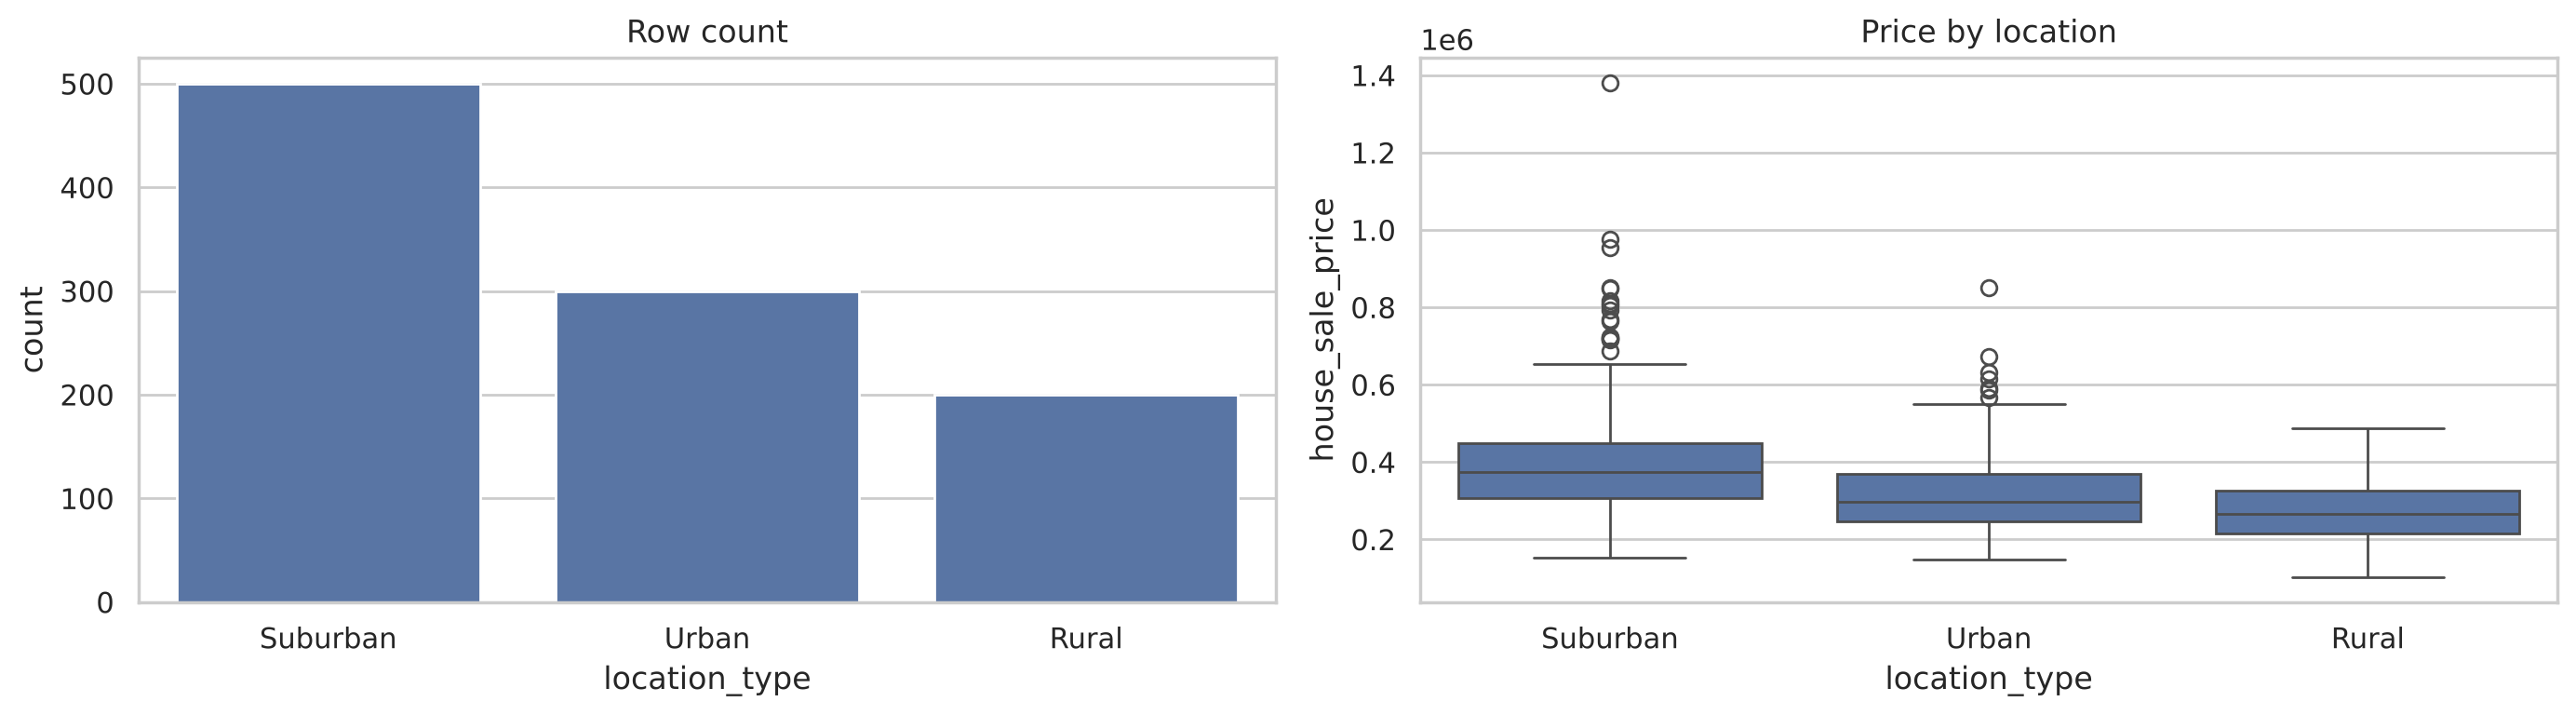

ANOVA on log(price): F_onewayResult(statistic=np.float64(104.04734066753903), pvalue=np.float64(9.130263695830925e-42))
Kruskal-Wallis on price: KruskalResult(statistic=np.float64(175.8065951488511), pvalue=np.float64(6.669340985964387e-39))


In [14]:
loc = df.groupby("location_type")[TARGET].agg(["count", "mean", "median", "std"])
loc["share"] = loc["count"] / len(df)
display(loc.sort_values("median", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = loc.sort_values("median", ascending=False).index
sns.countplot(data=df, x="location_type", order=order, ax=axes[0]); axes[0].set_title("Row count")
sns.boxplot(data=df, x="location_type", y=TARGET, order=order, ax=axes[1]); axes[1].set_title("Price by location")
plt.tight_layout(); plt.show()

groups = [np.log(g[TARGET]) for _, g in df.groupby("location_type")]
print("ANOVA on log(price):", stats.f_oneway(*groups))
print("Kruskal-Wallis on price:", stats.kruskal(*[g[TARGET] for _, g in df.groupby("location_type")]))

In [15]:
df.groupby("location_type")[NUM].mean().T

location_type,Rural,Suburban,Urban
property_size,"2,509.771","3,065.718","2,709.418"
number_of_bedrooms,3.392,3.682,3.425
number_of_bathrooms,3.170,3.758,3.314
age_of_property,26.352,17.365,20.553
proximity_to_public_transport,1.426,2.455,1.571
crime_rate_in_area,7.569,4.537,5.766
school_quality_score,6.246,7.456,6.721


**Findings**
- Counts are exactly 500 / 300 / 200 (Suburban / Urban / Rural) — a designed split, not a sample.
- **Suburban > Urban > Rural** in price. Urban being cheaper than Suburban runs against typical real-estate intuition; that is
  how this generator was built, so do not impose a "urban premium" prior.
- Location also shifts the features (Suburban homes are larger and farther from transport), so part of the raw location gap is
  confounded with size. Section 11 isolates the location effect after controlling for other features.
- Encoding: one-hot (3 levels, no high cardinality). Use stratified splits on `location_type` given the fixed 50/30/20 mix.

## 7. Bivariate analysis vs. target

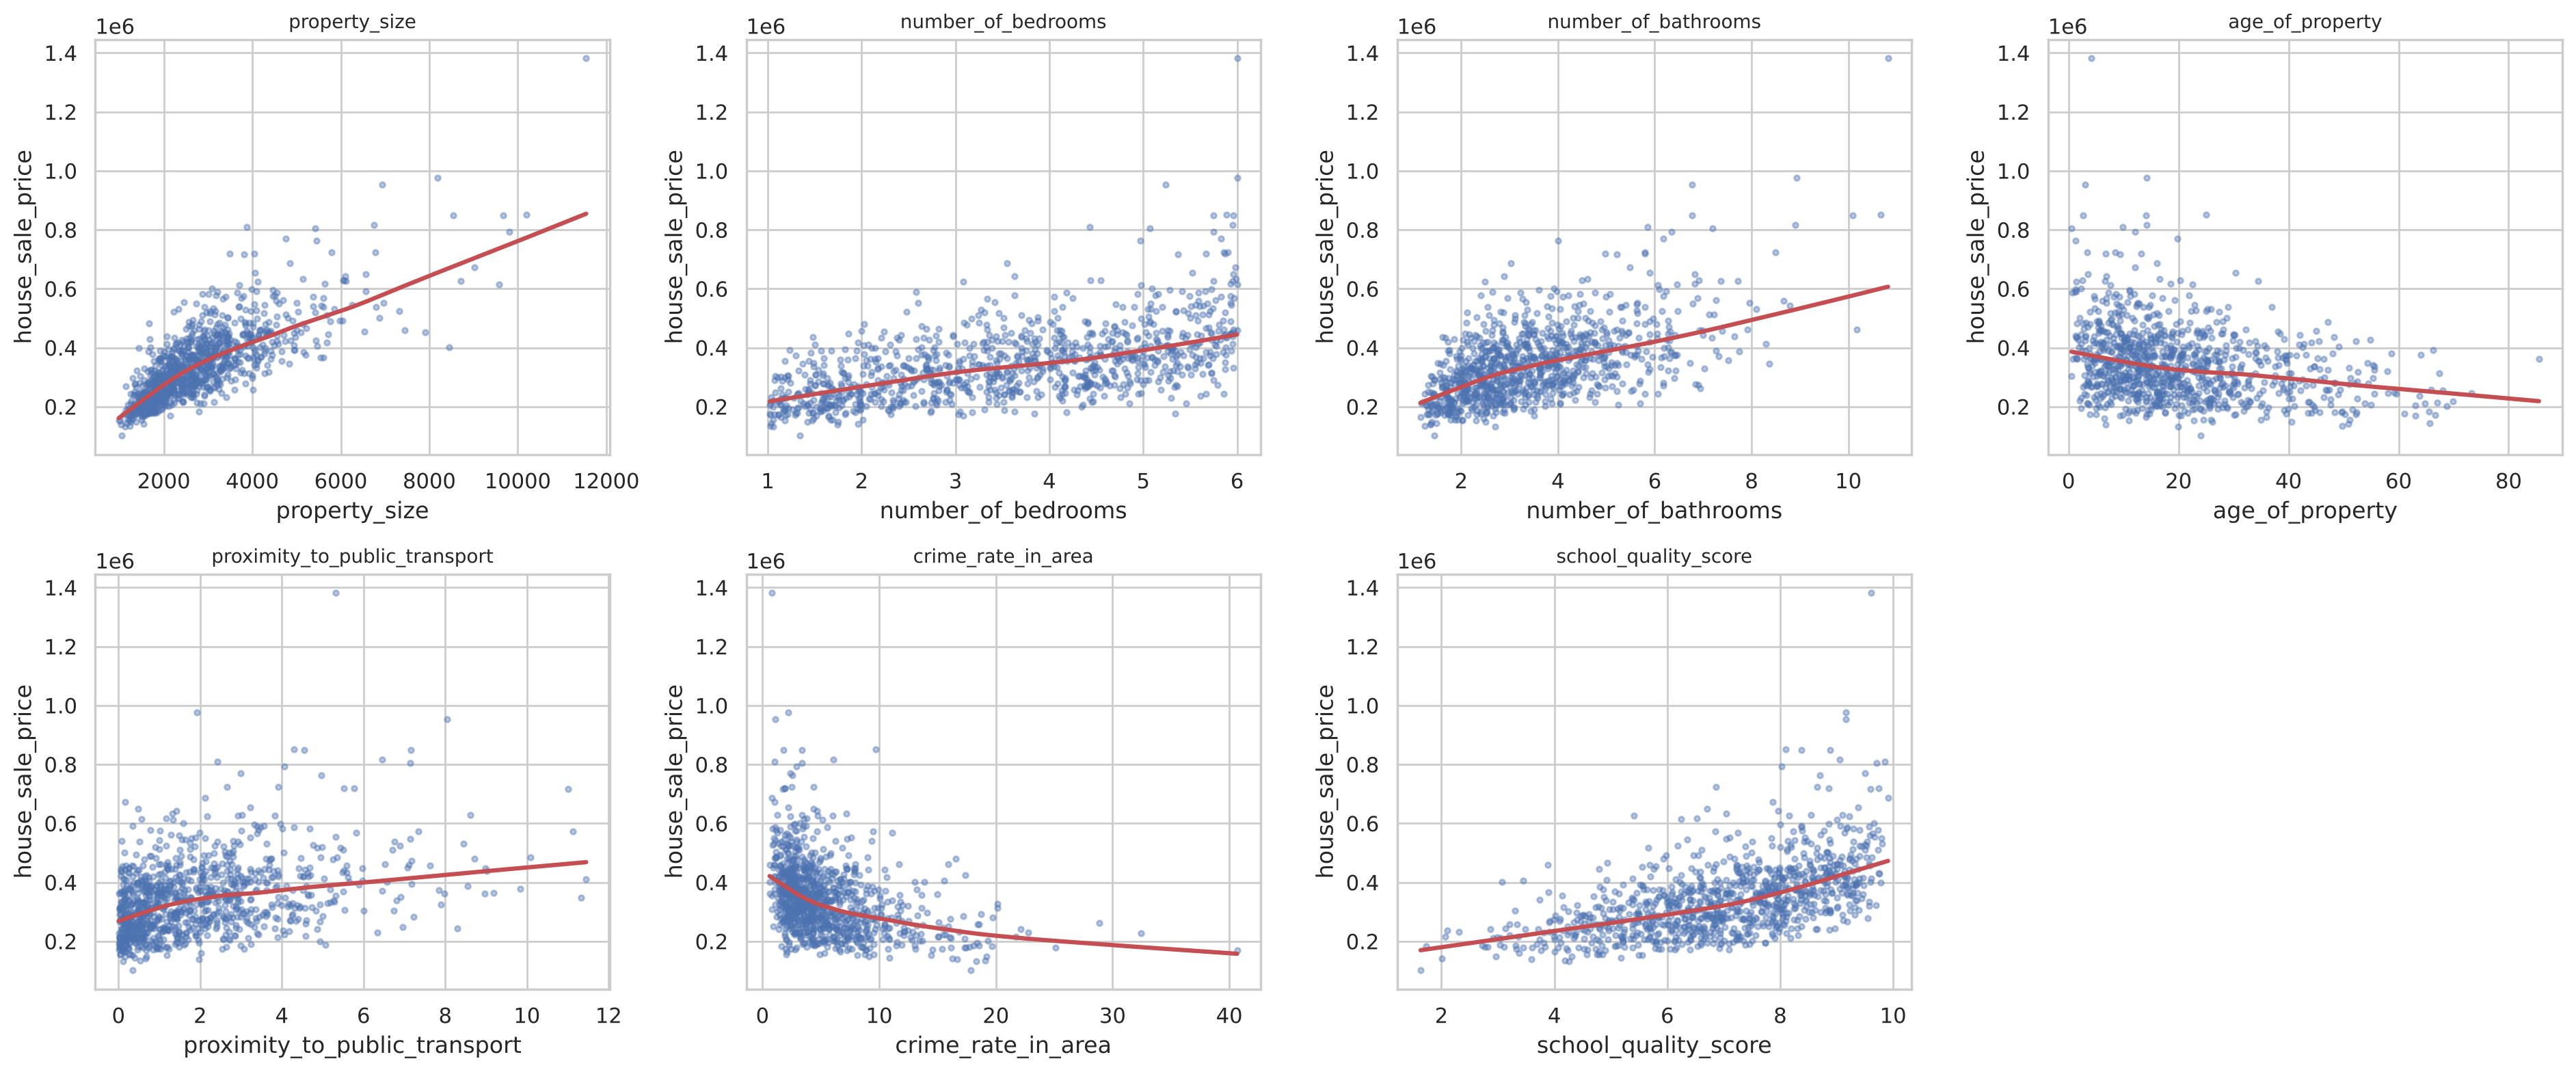

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, c in zip(axes.ravel(), NUM):
    sns.regplot(data=df, x=c, y=TARGET, ax=ax, lowess=True,
                scatter_kws={"s": 8, "alpha": 0.4}, line_kws={"color": "C3"})
    ax.set_title(c, fontsize=10)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [17]:
rel = pd.DataFrame({
    "pearson_raw": df[NUM].corrwith(df[TARGET]),
    "spearman": df[NUM].corrwith(df[TARGET], method="spearman"),
    "pearson_log_log": np.log(df[NUM]).corrwith(np.log(df[TARGET])),
}).sort_values("spearman", key=abs, ascending=False)
rel

,pearson_raw,spearman,pearson_log_log
property_size,0.775,0.773,0.791
school_quality_score,0.554,0.598,0.583
number_of_bedrooms,0.568,0.593,0.602
number_of_bathrooms,0.584,0.547,0.581
crime_rate_in_area,-0.365,-0.427,-0.446
proximity_to_public_transport,0.380,0.386,0.386
age_of_property,-0.278,-0.274,-0.296


**Findings**
- `property_size` dominates (Spearman ≈ 0.8). The LOWESS curve is concave in raw units — price grows sub-linearly with size —
  which is exactly what a log-log relationship looks like.
- `school_quality_score`, bedrooms and bathrooms are the next strongest positive drivers.
- `crime_rate_in_area` and `age_of_property` are negative; both curves flatten at high values (diminishing penalty) → log helps.
- **`proximity_to_public_transport` correlates *positively* with price.** If this column is a distance, larger distance =
  higher price, which is counter-intuitive. It may instead be an accessibility score, or it may proxy for the Suburban
  premium (Suburban homes have the highest mean "proximity" value). **The column's units/meaning must be confirmed** before
  any business interpretation; for prediction it is still a useful feature.
- Spearman > Pearson for most features → relationships are monotonic but non-linear in raw space.

## 8. Correlation & multicollinearity

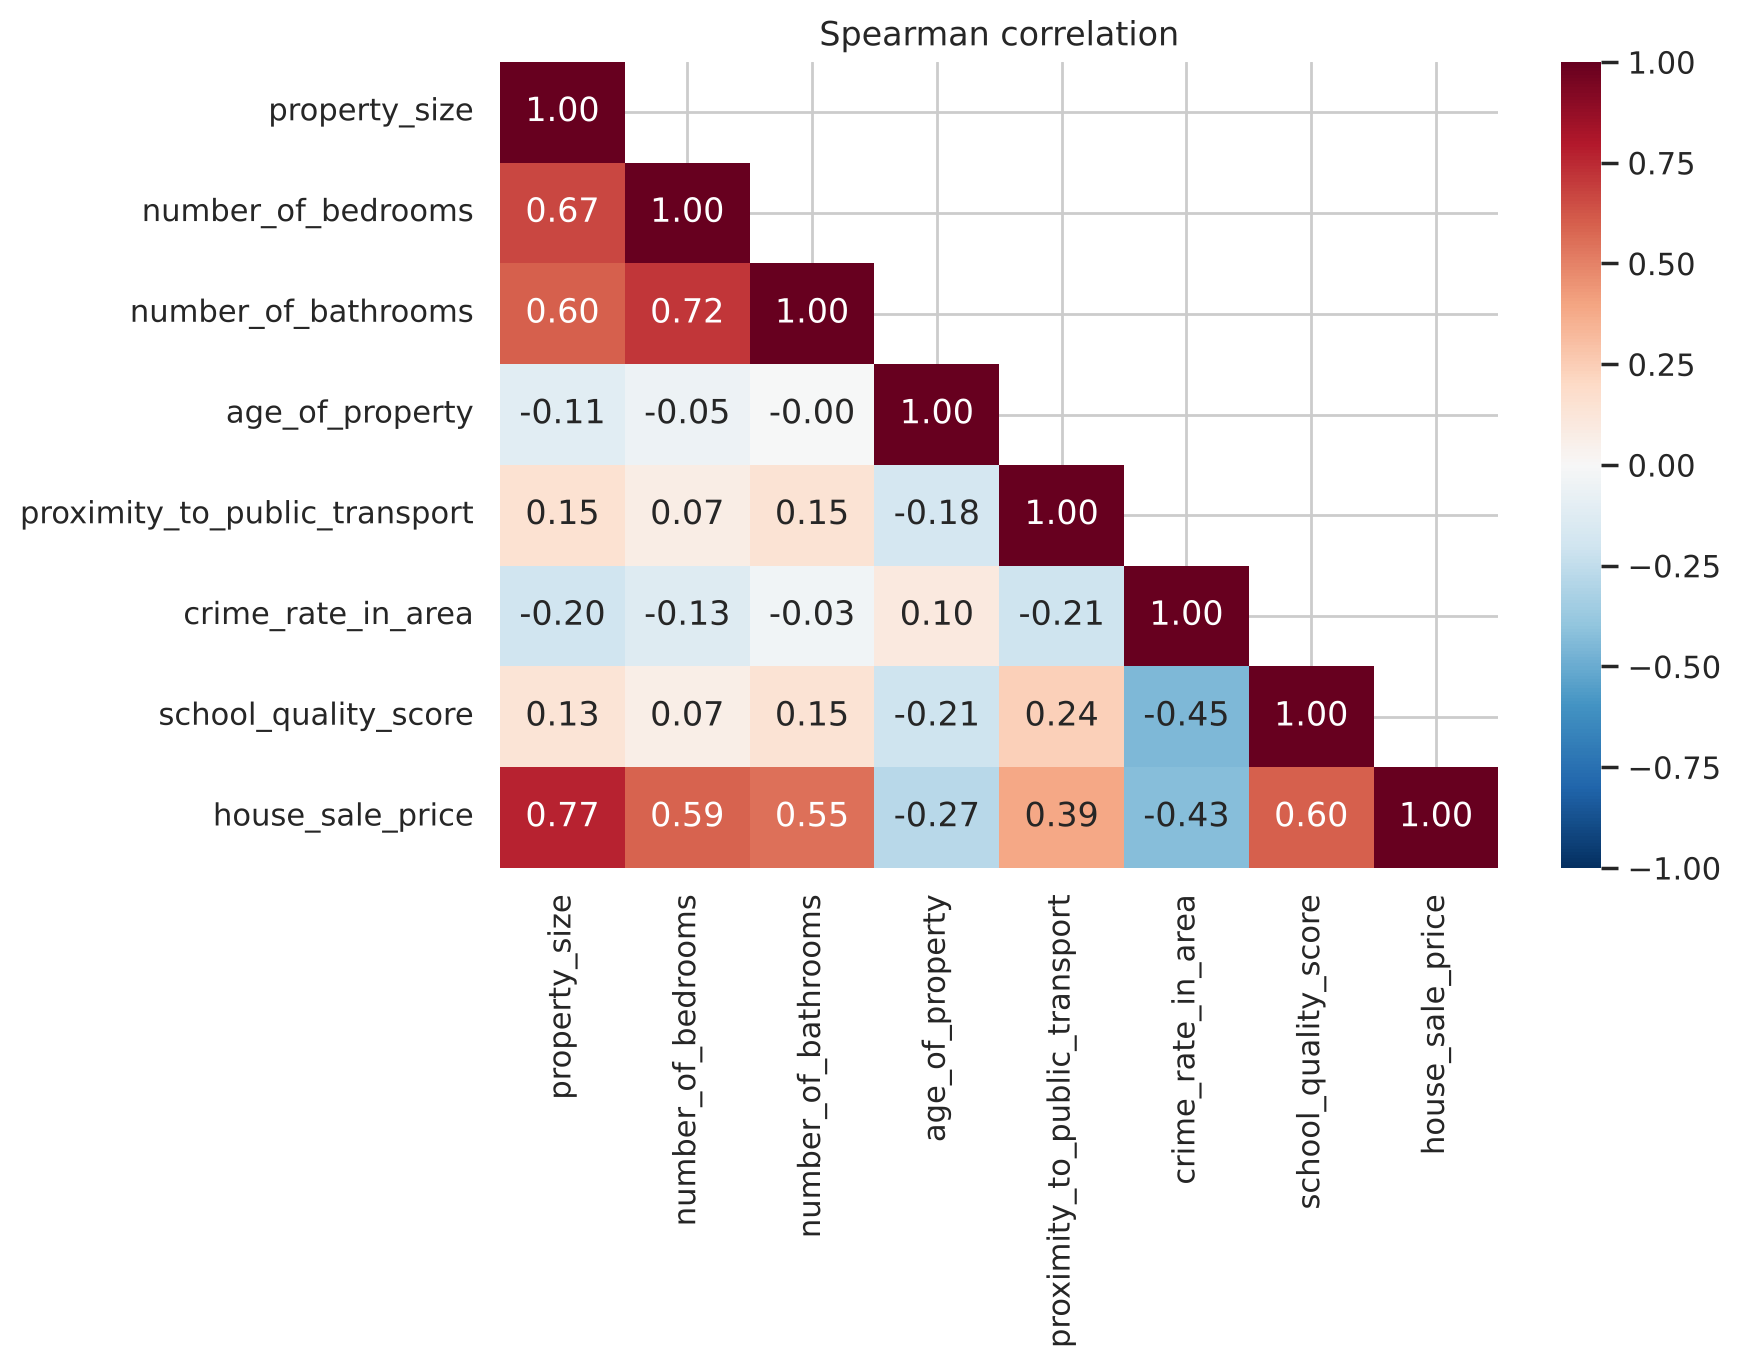

In [18]:
corr = df[NUM + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation"); plt.tight_layout(); plt.show()

In [19]:
X_vif = pd.get_dummies(df.drop(columns=TARGET), drop_first=True).astype(float)
X_vif = sm.add_constant(X_vif)
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
                index=X_vif.columns, name="VIF").drop("const").sort_values(ascending=False)
vif.to_frame()

,VIF
number_of_bathrooms,2.334
number_of_bedrooms,2.230
location_type_Suburban,2.099
property_size,1.895
location_type_Urban,1.834
school_quality_score,1.385
crime_rate_in_area,1.383
proximity_to_public_transport,1.133
age_of_property,1.112


**Findings**
- Size, bedrooms and bathrooms are inter-correlated (~0.6) — they all describe "how big the house is".
- All VIFs are well below 5, so multicollinearity is **moderate, not severe**. Plain OLS coefficients will be somewhat unstable
  between the three size variables; ridge regularisation or a combined size feature is sufficient.
- Neighbourhood variables (crime, school, transport) are only weakly correlated with each other and with size, so they carry
  independent signal.

## 9. Interactions with location

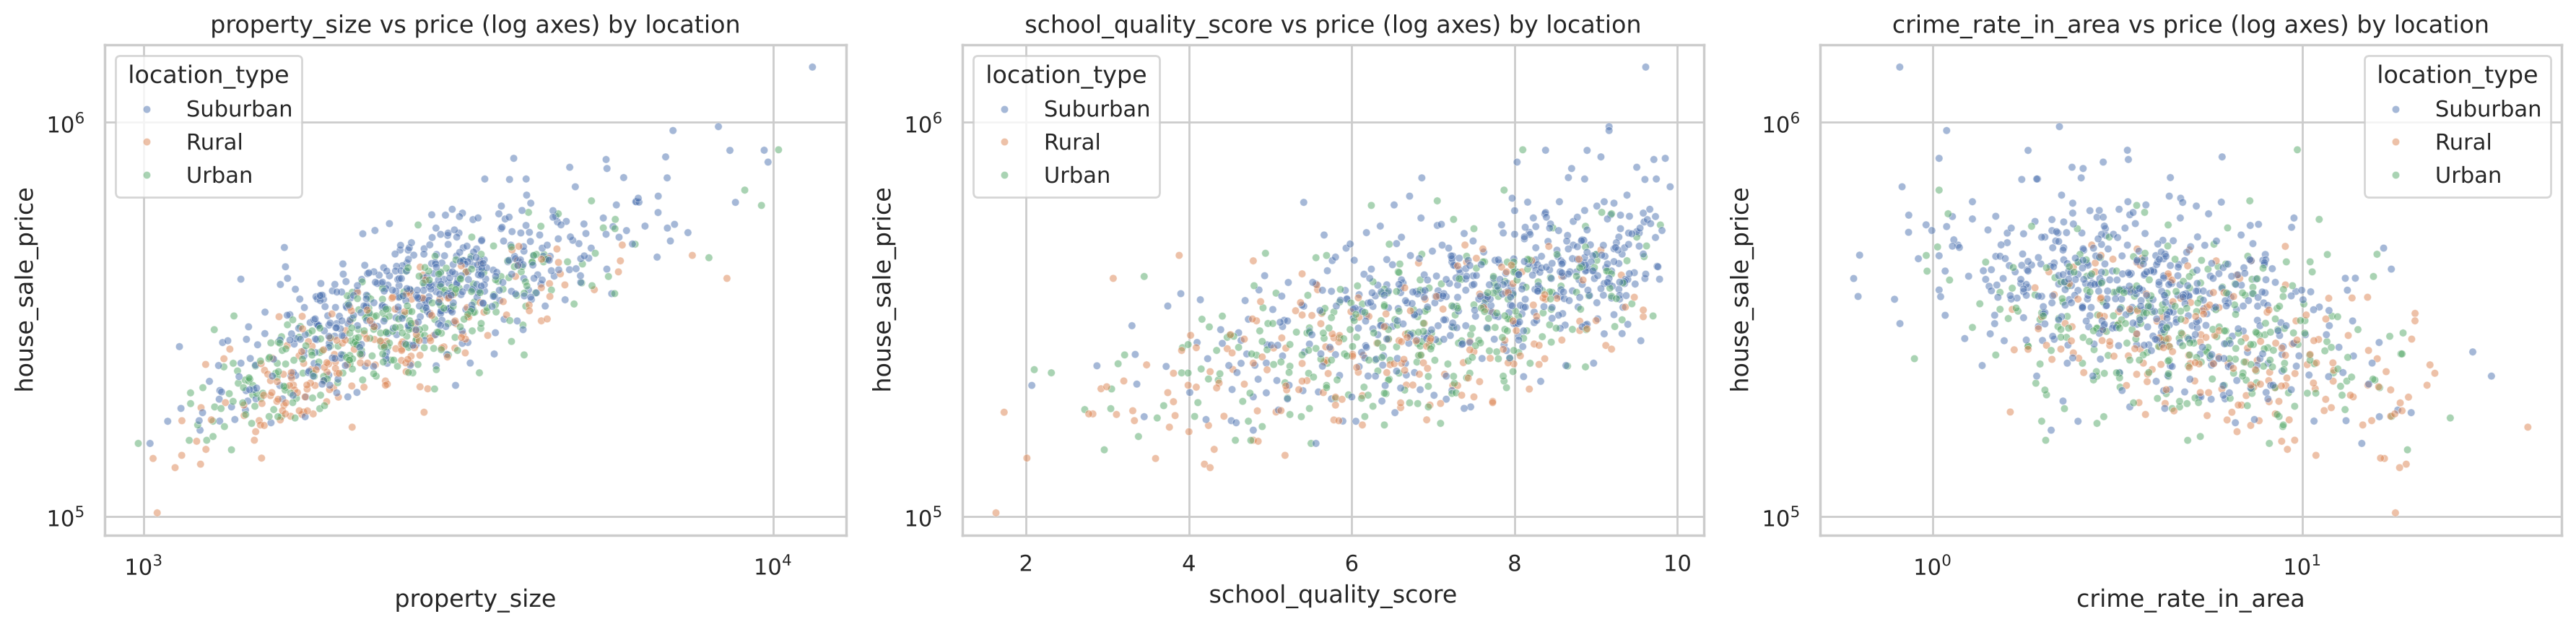

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, ["property_size", "school_quality_score", "crime_rate_in_area"]):
    sns.scatterplot(data=df, x=c, y=TARGET, hue="location_type", alpha=0.5, s=14, ax=ax)
    ax.set_yscale("log")
    if c in ("property_size", "crime_rate_in_area"):
        ax.set_xscale("log")
    ax.set_title(f"{c} vs price (log axes) by location")
plt.tight_layout(); plt.show()

In [21]:
rows = []
for loc_name, g in df.groupby("location_type"):
    for c in ["property_size", "crime_rate_in_area", "proximity_to_public_transport", "age_of_property"]:
        slope = np.polyfit(np.log(g[c]), np.log(g[TARGET]), 1)[0]
        rows.append((loc_name, c, slope))
    slope = np.polyfit(g["school_quality_score"], np.log(g[TARGET]), 1)[0]
    rows.append((loc_name, "school_quality_score", slope))
pd.DataFrame(rows, columns=["location", "feature", "elasticity_or_slope"]) \
  .pivot(index="feature", columns="location", values="elasticity_or_slope")

location,Rural,Suburban,Urban
feature,,,
age_of_property,-0.090,-0.100,-0.081
crime_rate_in_area,-0.209,-0.196,-0.120
property_size,0.637,0.622,0.620
proximity_to_public_transport,0.084,0.101,0.048
school_quality_score,0.092,0.122,0.100


**Finding:** on log-log axes the three location groups form roughly **parallel bands** — similar slopes, different intercepts.
Location acts mainly as a **multiplicative level shift**, not a slope modifier. Interaction terms are therefore low priority;
test them in modelling but don't expect large gains.

## 10. Outliers & influential points

In [22]:
num = df[NUM + [TARGET]]
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
iqr_raw = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
lnum = np.log(num)
lq1, lq3 = lnum.quantile(0.25), lnum.quantile(0.75)
liqr = lq3 - lq1
iqr_log = ((lnum < lq1 - 1.5 * liqr) | (lnum > lq3 + 1.5 * liqr)).sum()
pd.DataFrame({"IQR outliers (raw)": iqr_raw, "IQR outliers (log)": iqr_log})

,IQR outliers (raw),IQR outliers (log)
property_size,46,12
number_of_bedrooms,0,0
number_of_bathrooms,23,2
age_of_property,40,20
proximity_to_public_transport,41,28
crime_rate_in_area,56,5
school_quality_score,6,29
house_sale_price,22,7


Most raw-scale 'outliers' disappear after a log transform — they are tail values, not anomalies. Influence is the better test:

Cook's D > 4/n: 54 rows | |studentized resid| > 3: 4 rows


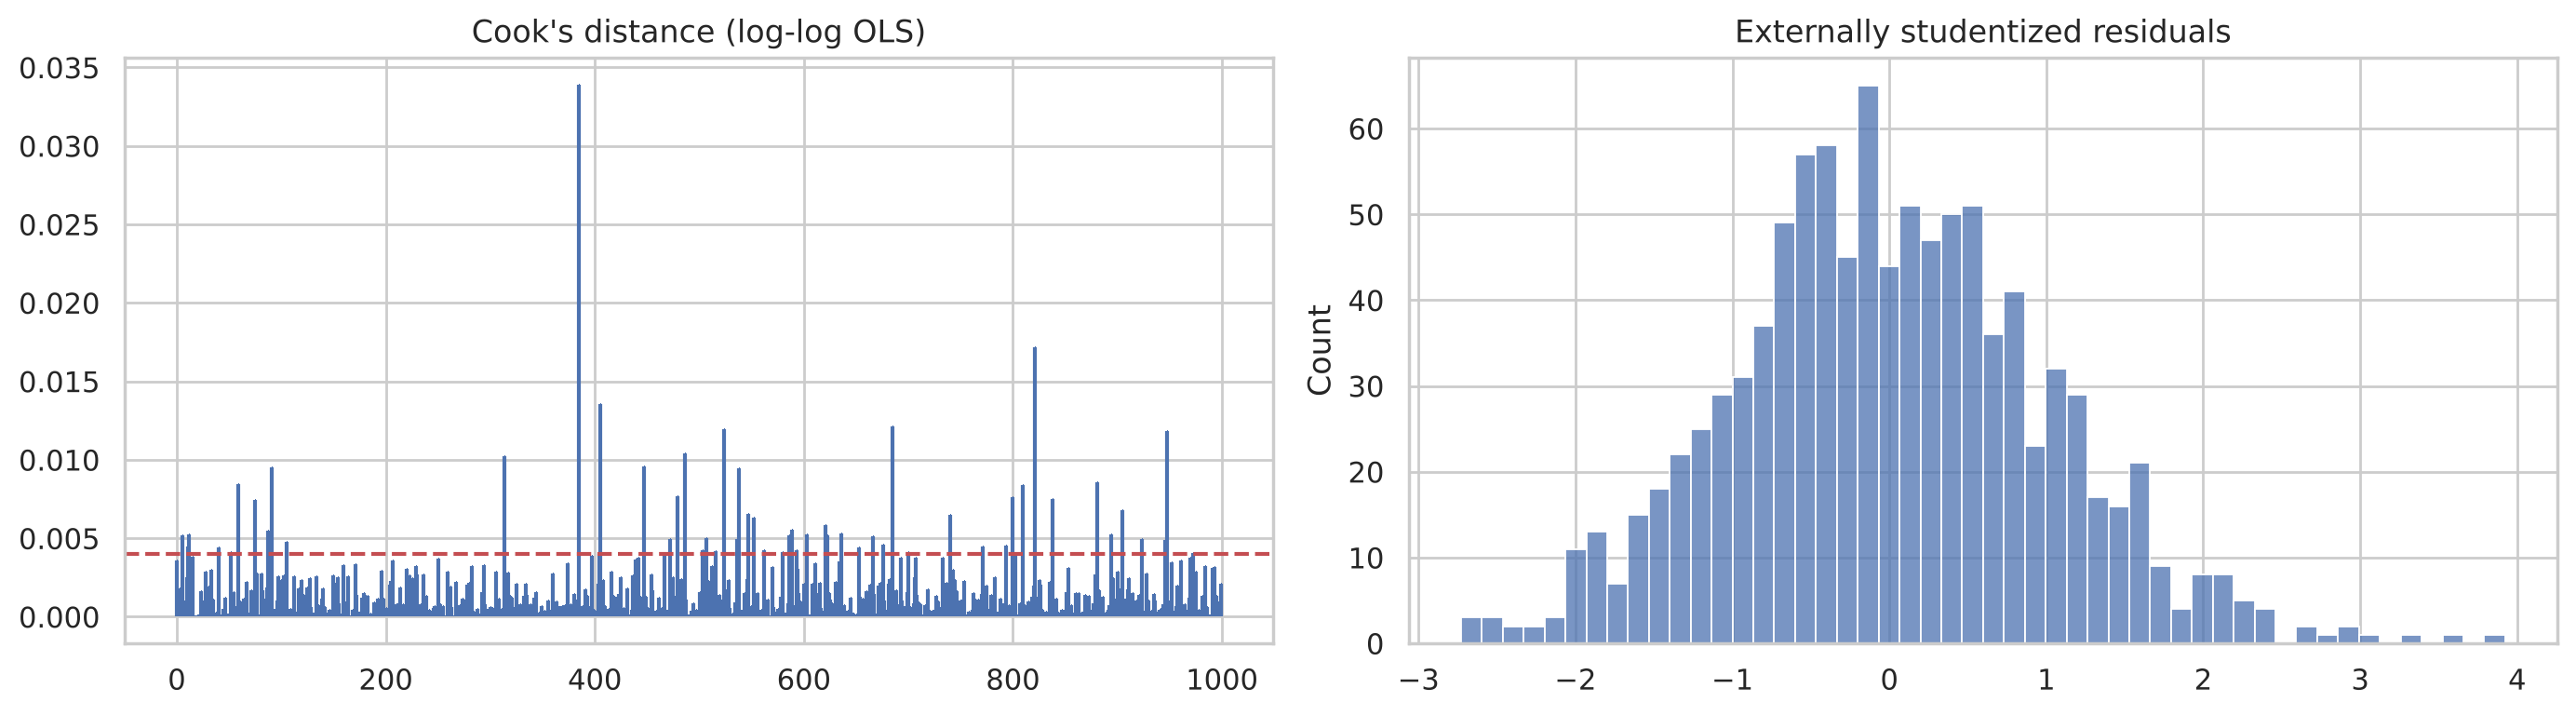

,property_size,number_of_bedrooms,number_of_bathrooms,location_type,age_of_property,proximity_to_public_transport,crime_rate_in_area,school_quality_score,house_sale_price,cooks_d,stud_resid
385,"11,545.780",6.000,10.820,Suburban,4.200,5.320,0.814,9.610,"1,381,318.560",0.034,2.826
821,"1,920.030",2.890,2.080,Suburban,43.530,0.029,15.100,3.360,"216,570.680",0.017,2.946
405,"3,870.510",4.430,5.850,Suburban,9.840,2.430,1.040,9.850,"810,322.530",0.014,3.924
685,"1,672.130",4.410,5.630,Suburban,1.500,4.470,1.180,9.240,"481,258.200",0.012,2.156
524,"1,966.000",4.950,3.310,Rural,2.840,0.213,5.250,7.990,"243,722.220",0.012,-2.572
947,"2,042.940",1.830,1.730,Rural,2.330,0.196,22.790,3.810,"230,719.520",0.012,2.333
486,"3,435.360",5.960,10.180,Urban,21.680,2.780,15.900,6.860,"462,599.510",0.010,1.769
313,"2,644.360",3.610,4.580,Urban,67.400,0.042,10.150,6.360,"313,787.080",0.010,2.642


In [23]:
X_log = pd.get_dummies(df.drop(columns=TARGET), drop_first=True).astype(float)
for c in ["property_size", "crime_rate_in_area", "proximity_to_public_transport", "age_of_property"]:
    X_log[c] = np.log(X_log[c])
ols = sm.OLS(np.log(df[TARGET]), sm.add_constant(X_log)).fit()
infl = ols.get_influence()
cooks = infl.cooks_distance[0]
stud = infl.resid_studentized_external
thr = 4 / len(df)
print(f"Cook's D > 4/n: {(cooks > thr).sum()} rows | |studentized resid| > 3: {(np.abs(stud) > 3).sum()} rows")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].stem(cooks, markerfmt=",", basefmt=" "); axes[0].axhline(thr, color="C3", ls="--")
axes[0].set_title("Cook's distance (log-log OLS)")
sns.histplot(stud, bins=50, ax=axes[1]); axes[1].set_title("Externally studentized residuals")
plt.tight_layout(); plt.show()

top = df.assign(cooks_d=cooks, stud_resid=stud).sort_values("cooks_d", ascending=False).head(8)
top

**Finding:** 54 rows exceed the 4/n Cook's-distance rule of thumb, but that rule is deliberately loose; the largest Cook's D
is only ≈ 0.03 (far below the 0.5–1 range that signals a dominating point), and only 4 residuals fall beyond ±3. **Recommendation:** do not drop rows. Use
log transforms (which neutralise most of the leverage) and, if needed, a robust loss (Huber) as a sensitivity check.

## 11. Functional-form diagnostics

Quick 5-fold cross-validated linear regressions are used here **only to test which representation of the data is most linear**,
not as final models. R² is reported on the scale each model was fit on, plus RMSE in dollars for comparability.

In [24]:
kf = KFold(5, shuffle=True, random_state=RNG)
X_raw = pd.get_dummies(df.drop(columns=TARGET), drop_first=True).astype(float)
y_raw = df[TARGET]

def cv_dollar_rmse(X, y_fit, back):
    pred = back(cross_val_predict(LinearRegression(), X, y_fit, cv=kf))
    return np.sqrt(np.mean((pred - y_raw) ** 2))

results = pd.DataFrame({
    "spec": ["raw X → raw y", "raw X → log y", "log(skewed X) → log y"],
    "cv_R2_fit_scale": [
        cross_val_score(LinearRegression(), X_raw, y_raw, cv=kf).mean(),
        cross_val_score(LinearRegression(), X_raw, np.log(y_raw), cv=kf).mean(),
        cross_val_score(LinearRegression(), X_log, np.log(y_raw), cv=kf).mean(),
    ],
    "cv_RMSE_$": [
        cv_dollar_rmse(X_raw, y_raw, lambda p: p),
        cv_dollar_rmse(X_raw, np.log(y_raw), np.exp),
        cv_dollar_rmse(X_log, np.log(y_raw), np.exp),
    ],
})
rf_r2 = cross_val_score(RandomForestRegressor(400, random_state=RNG, n_jobs=-1), X_raw, np.log(y_raw), cv=kf).mean()
print(f"Reference: random forest on raw X → log y, CV R² = {rf_r2:.3f}")
results

Reference: random forest on raw X → log y, CV R² = 0.901


,spec,cv_R2_fit_scale,cv_RMSE_$
0,raw X → raw y,0.871,"44,407.121"
1,raw X → log y,0.900,"44,014.257"
2,log(skewed X) → log y,0.931,"35,907.879"


In [25]:
print(ols.summary().tables[1])

                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             8.2816      0.078    105.802      0.000       8.128       8.435
property_size                     0.4763      0.010     47.197      0.000       0.456       0.496
number_of_bedrooms                0.0370      0.003     12.374      0.000       0.031       0.043
number_of_bathrooms               0.0015      0.003      0.569      0.569      -0.004       0.007
age_of_property                  -0.0335      0.004     -9.200      0.000      -0.041      -0.026
proximity_to_public_transport     0.0414      0.002     17.471      0.000       0.037       0.046
crime_rate_in_area               -0.0202      0.005     -4.147      0.000      -0.030      -0.011
school_quality_score              0.0848      0.002     42.010      0.000       0.081       0.089
location_type_Suburb

**Key finding — the data is close to multiplicative (log-linear).** A plain linear model on log-transformed skewed features and
log price explains roughly 93% of variance out of sample, clearly better than the raw-scale fit and better than an untuned random
forest on raw features. This strongly suggests the generator is approximately:

`log(price) ≈ β₀ + 0.48·log(size) + β·school + … + location offset + noise`

Implications:
- Linear/ridge on log-log features is a **very strong baseline**; complex models must beat it on CV to justify themselves.
- The `property_size` elasticity ≈ 0.48: doubling size raises price by ~2^0.48 − 1 ≈ 39%, all else equal.
- Holding other features fixed, `number_of_bathrooms` adds almost nothing — its raw correlation with price is mostly borrowed from size.
- After controlling for size and neighbourhood, Suburban still carries a premium (~8% over Rural) and Urban a small one (~3%).

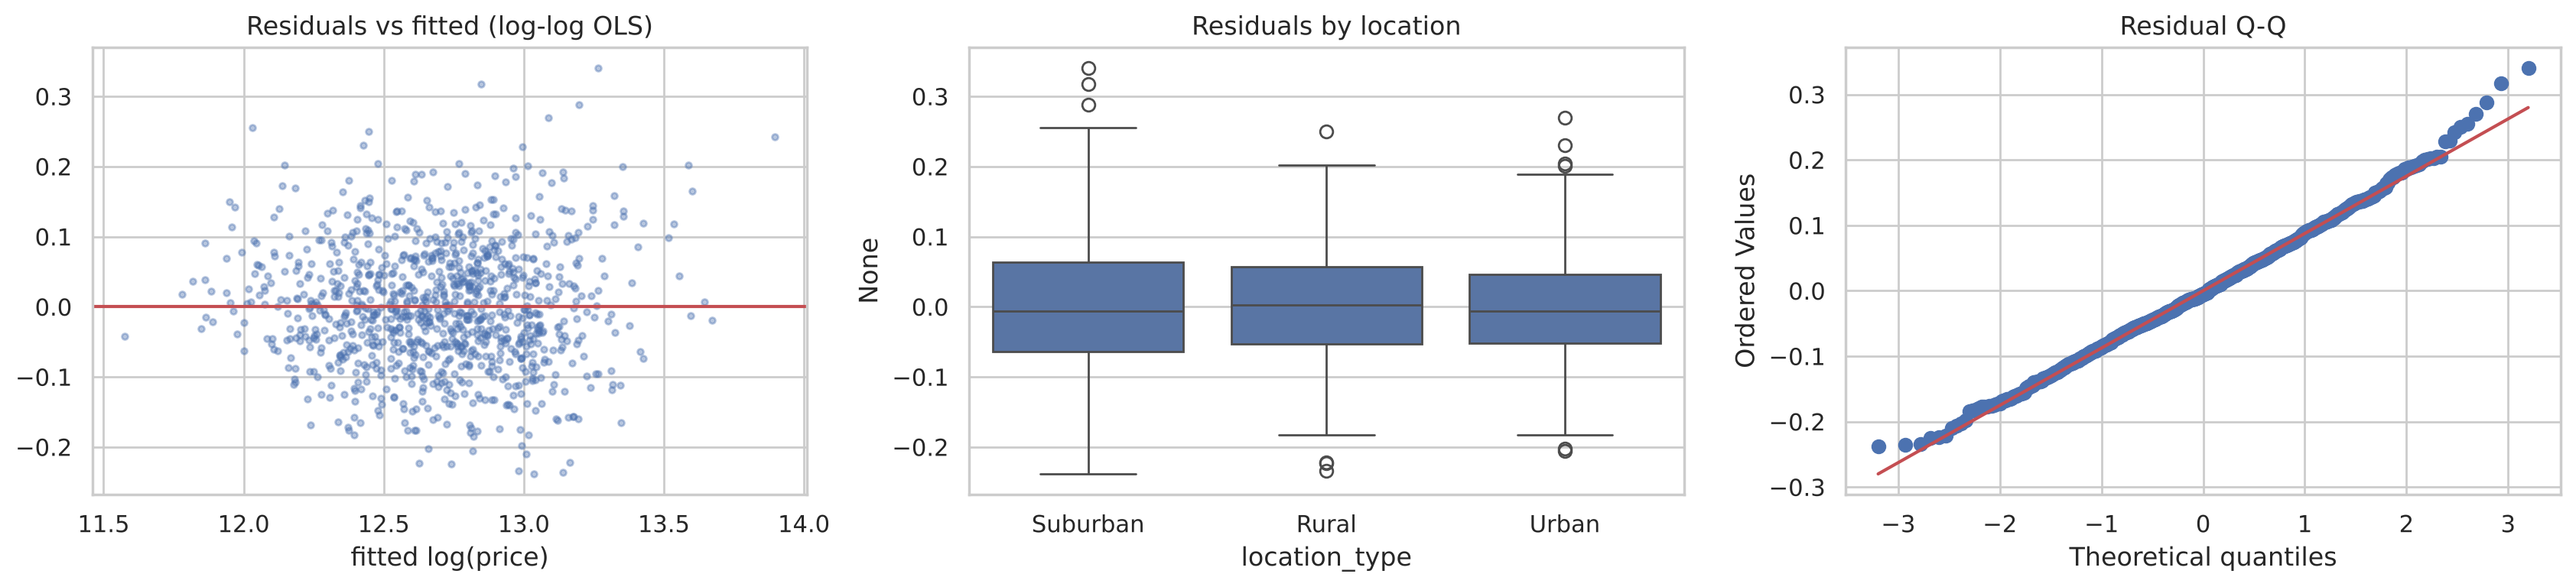

In [26]:
fitted = ols.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].scatter(fitted, ols.resid, s=8, alpha=0.4); axes[0].axhline(0, color="C3")
axes[0].set_title("Residuals vs fitted (log-log OLS)"); axes[0].set_xlabel("fitted log(price)")
sns.boxplot(x=df["location_type"], y=ols.resid, ax=axes[1]); axes[1].set_title("Residuals by location")
stats.probplot(ols.resid, plot=axes[2]); axes[2].set_title("Residual Q-Q")
plt.tight_layout(); plt.show()

Residuals show no clear curvature or funnel shape and are centred within each location group — the log-log form captures the main structure.

## 12. Feature relevance

In [27]:
mi = pd.Series(mutual_info_regression(X_raw, np.log(y_raw), random_state=RNG), index=X_raw.columns)

rf = RandomForestRegressor(400, random_state=RNG, n_jobs=-1).fit(X_raw, np.log(y_raw))
perm = permutation_importance(rf, X_raw, np.log(y_raw), n_repeats=10, random_state=RNG, n_jobs=-1)

std_coef = pd.Series(ols.params.drop("const") * X_log.std(), index=X_log.columns)

rel_tbl = pd.DataFrame({
    "mutual_info": mi,
    "rf_permutation": pd.Series(perm.importances_mean, index=X_raw.columns),
    "std_coef_loglog_OLS": std_coef,
}).sort_values("mutual_info", ascending=False)
rel_tbl

,mutual_info,rf_permutation,std_coef_loglog_OLS
property_size,0.518,0.863,0.191
school_quality_score,0.227,0.443,0.139
number_of_bedrooms,0.221,0.033,0.053
number_of_bathrooms,0.193,0.008,0.002
location_type_Suburban,0.096,0.009,0.040
proximity_to_public_transport,0.092,0.043,0.052
crime_rate_in_area,0.087,0.010,-0.014
age_of_property,0.058,0.015,-0.027
location_type_Urban,0.029,0.001,0.014


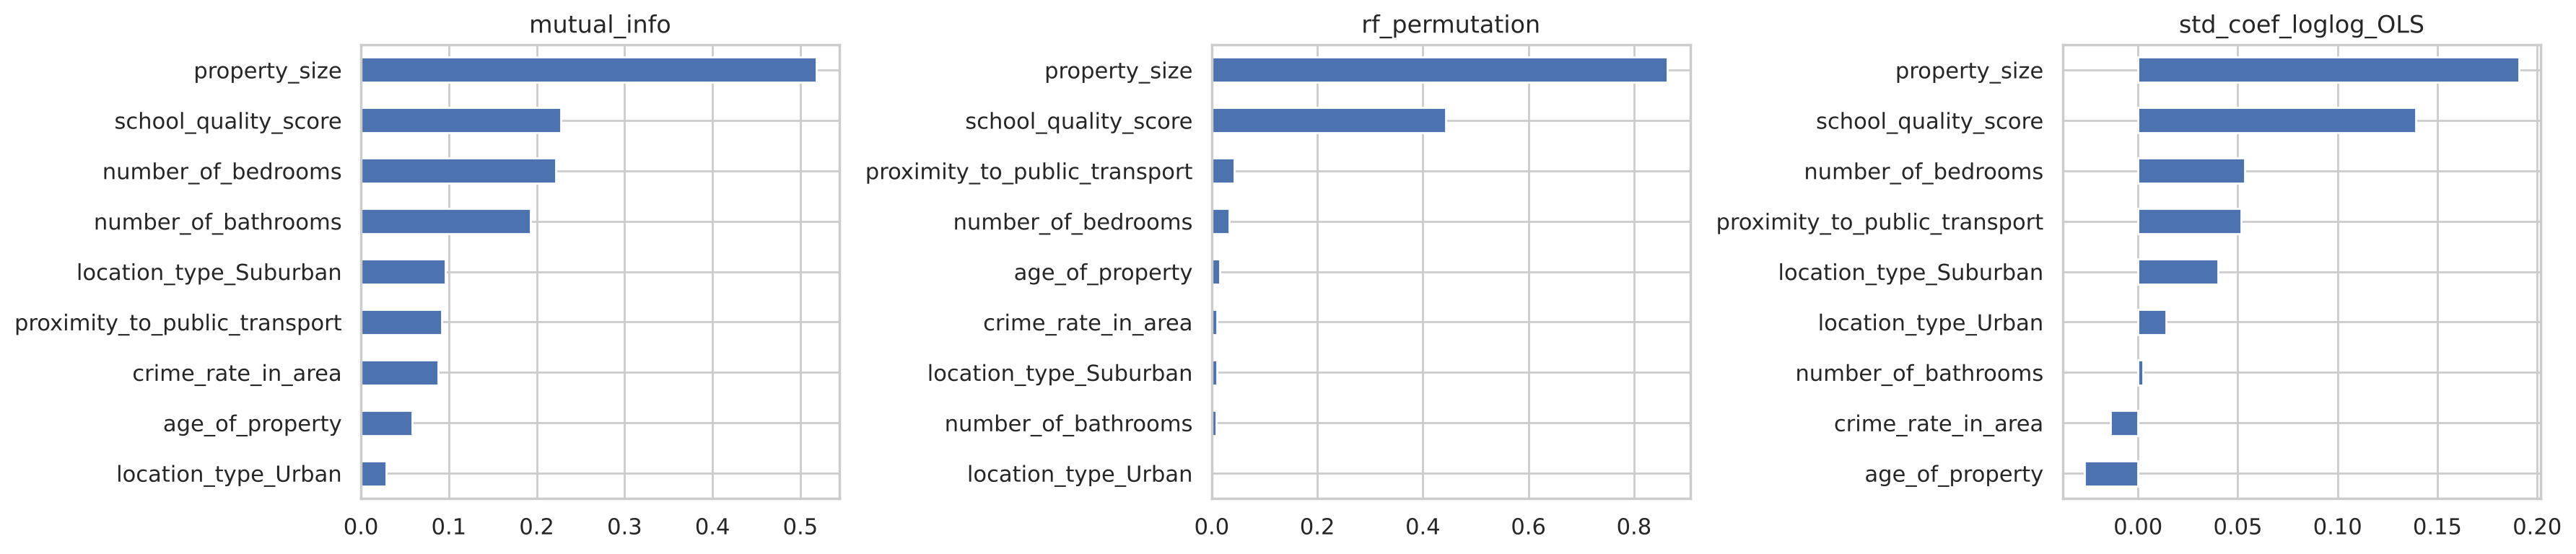

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, rel_tbl.columns):
    rel_tbl[col].sort_values().plot.barh(ax=ax, color="C0")
    ax.set_title(col)
plt.tight_layout(); plt.show()

Note: random-forest permutation importance is computed on training data here, so it measures what the forest *uses*, not
generalisation. It agrees with the other two views on the ranking.

**Ranking (conditional effects, std. coefficients):** `property_size` ≫ `school_quality_score` > `number_of_bedrooms` ≈
`proximity_to_public_transport` > Suburban > `age_of_property` > `crime_rate_in_area` > `number_of_bathrooms` (≈ 0).

**Marginal vs conditional disagreement worth knowing:** crime has a solid raw correlation with price (Spearman −0.43) but a
small conditional effect (std. coef −0.014). Crime is lower where schools are better and in Suburban areas, so most of its
apparent effect is carried by those variables. Bathrooms show the same pattern relative to size. Mutual information ranks
bedrooms/bathrooms high because it is marginal — it cannot see redundancy.

## 13. Feature-engineering candidates (quick check)

In [29]:
fe = df.copy()
fe["log_size"] = np.log(fe.property_size)
fe["size_per_bedroom"] = fe.property_size / fe.number_of_bedrooms
fe["bath_per_bed"] = fe.number_of_bathrooms / fe.number_of_bedrooms
fe["rooms_total"] = fe.number_of_bedrooms + fe.number_of_bathrooms
fe["log_crime"] = np.log(fe.crime_rate_in_area)
fe["school_x_crime"] = fe.school_quality_score / fe.crime_rate_in_area
fe["is_new"] = (fe.age_of_property < 5).astype(int)
new = ["size_per_bedroom", "bath_per_bed", "rooms_total", "school_x_crime", "is_new"]
fe[new].corrwith(np.log(fe[TARGET]), method="spearman").sort_values(key=abs, ascending=False).to_frame("spearman_vs_log_price")

,spearman_vs_log_price
rooms_total,0.614
school_x_crime,0.529
is_new,0.139
bath_per_bed,-0.129
size_per_bedroom,0.063


In [30]:
base = X_log.copy()
cands = {
    "baseline (log-log)": base,
    "+ log(size_per_bedroom)": base.assign(lspb=np.log(fe.size_per_bedroom)),
    "+ bath_per_bed": base.assign(bpb=fe.bath_per_bed),
    "+ school/crime": base.assign(sc=np.log(fe.school_x_crime)),
    "+ size×location": base.assign(s_sub=base.property_size * base.location_type_Suburban,
                                   s_urb=base.property_size * base.location_type_Urban),
    "- bathrooms": base.drop(columns="number_of_bathrooms"),
}
pd.Series({k: cross_val_score(LinearRegression(), v, np.log(y_raw), cv=kf).mean() for k, v in cands.items()},
          name="cv_R2_log").to_frame()

,cv_R2_log
baseline (log-log),0.931
+ log(size_per_bedroom),0.931
+ bath_per_bed,0.931
+ school/crime,0.933
+ size×location,0.931
- bathrooms,0.931


Engineered ratios and interactions add little or nothing on top of the log-log baseline, and dropping bathrooms costs
essentially nothing. On this dataset, **getting the transform right matters far more than inventing features**. Keep the
feature set small.

## 14. Summary of findings & recommendations

### Data quality
| Issue | Evidence | Action |
|---|---|---|
| Missing values | None in any column | No imputation needed; still add an imputer in the pipeline for robustness |
| Duplicates | 0 exact, 0 feature-level | None |
| Fractional bedroom/bathroom counts | ~99% non-integer | Keep continuous; document that this will not transfer to integer real-world data |
| Bedroom ceiling | 4 rows exactly at 6.0 | Treat as censored; minor impact |
| Ambiguous `proximity_to_public_transport` | Positive correlation with price | Confirm units (distance vs. score) before interpreting |
| Designed category split | 500/300/200 exactly | Stratify train/test split on `location_type` |

### Distributions
- Target is right-skewed (≈1.6) → **model log(price)**.
- Size, crime, transport proximity, age and bathrooms are log-normal-ish → **log-transform them**.
- Raw-scale "outliers" are mostly distribution tails; very few influential points → **do not remove rows**.

### Relationships
- `property_size` is the dominant driver (price elasticity ≈ 0.48).
- School quality (+) is the strongest neighbourhood signal. Crime (−) looks strong marginally but most of its effect is shared
  with school quality and location; its conditional effect is small.
- Location is a level shift: Suburban > Urban > Rural, consistent across features.
- Bedrooms/bathrooms are largely redundant with size once size is in the model.
- A linear model on log-log features reaches ≈ 0.93 CV R² → the data generating process is close to multiplicative.

### Recommended preprocessing pipeline
1. Stratified train/test split by `location_type` (fit all transforms on train only).
2. `log` transform: target, `property_size`, `crime_rate_in_area`, `proximity_to_public_transport`, `age_of_property`
   (leave `school_quality_score` and bedrooms unlogged).
3. One-hot encode `location_type` (drop one level for linear models).
4. Standardise numeric features for regularised linear models (not needed for trees).
5. Baseline: Ridge on log-log features. Challengers: gradient boosting (LightGBM/XGBoost) on the same features.
6. Report metrics in dollars (RMSE, MAE) and in % (MAPE) after back-transforming; apply Duan's smearing if mean predictions are required.